# Practical 8 - Decision Tree Classification
Dataset: Students Performance (1000 students) - predict whether a student receives a
free/reduced lunch from exam scores and background information.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.feature_selection import mutual_info_classif

SEED = 11
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("StudentsPerformance.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

raw = pd.read_csv(DATA / "StudentsPerformance.csv")
raw.columns = [c.replace(" ", "_").replace("/", "_") for c in raw.columns]

y = (raw["lunch"] == "free/reduced").astype(int)          # 1 = free/reduced lunch
X = pd.get_dummies(raw.drop(columns="lunch"), drop_first=True, dtype=int)

print("Students           :", len(raw))
print("Standard lunch     :", int((y == 0).sum()))
print("Free/reduced lunch :", int((y == 1).sum()))
print("Majority-class baseline accuracy: %.3f" % (1 - y.mean()))
print("Number of features after encoding:", X.shape[1])

Students           : 1000
Standard lunch     : 645
Free/reduced lunch : 355
Majority-class baseline accuracy: 0.645
Number of features after encoding: 14


## 1. Train / test split (80 / 20, stratified)

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Training set:", X_tr.shape, "| Test set:", X_te.shape)
print("Share of free/reduced lunch  train: %.3f  test: %.3f" % (y_tr.mean(), y_te.mean()))

Training set: (800, 14) | Test set: (200, 14)
Share of free/reduced lunch  train: 0.355  test: 0.355


## 2. Which features look informative?

In [3]:
mi = pd.Series(mutual_info_classif(X_tr, y_tr, random_state=SEED), index=X.columns)
corr = X_tr.assign(target=y_tr).corr()["target"].drop("target")
ranking = pd.DataFrame({"mutual_info": mi, "correlation": corr}).sort_values("mutual_info", ascending=False)
print(ranking.round(4).head(8).to_string())

                                          mutual_info  correlation
math_score                                     0.0690      -0.3686
reading_score                                  0.0504      -0.2377
test_preparation_course_none                   0.0398      -0.0255
race_ethnicity_group B                         0.0269       0.0311
writing_score                                  0.0220      -0.2533
race_ethnicity_group E                         0.0084      -0.0486
parental_level_of_education_high school        0.0083       0.0013
parental_level_of_education_some college       0.0032       0.0217


## 3. Entropy vs Gini at different depths

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
records = []
for criterion in ("entropy", "gini"):
    for depth in (2, 3, 4, 5, 6, None):
        tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=SEED)
        cv_acc = cross_val_score(tree, X_tr, y_tr, cv=cv).mean()
        tree.fit(X_tr, y_tr)
        records.append({"criterion": criterion, "max_depth": depth if depth else 0,
                        "train_acc": tree.score(X_tr, y_tr), "cv_acc": cv_acc,
                        "test_acc": tree.score(X_te, y_te)})
sweep = pd.DataFrame(records)
print("(max_depth 0 means 'no limit')")
print(sweep.round(3).to_string(index=False))

limited = sweep[sweep["max_depth"] > 0]
best = limited.sort_values(["cv_acc", "max_depth"], ascending=[False, True]).iloc[0]
print(f"\nChosen by 5-fold cross-validation on the training data: {best['criterion']}, "
      f"max_depth = {int(best['max_depth'])}")

(max_depth 0 means 'no limit')
criterion  max_depth  train_acc  cv_acc  test_acc
  entropy          2      0.709   0.696     0.700
  entropy          3      0.718   0.696     0.670
  entropy          4      0.721   0.675     0.685
  entropy          5      0.736   0.674     0.690
  entropy          6      0.765   0.668     0.675
  entropy          0      0.999   0.599     0.590
     gini          2      0.709   0.696     0.700
     gini          3      0.718   0.699     0.670
     gini          4      0.721   0.681     0.685
     gini          5      0.738   0.658     0.680
     gini          6      0.772   0.658     0.670
     gini          0      0.999   0.591     0.605

Chosen by 5-fold cross-validation on the training data: gini, max_depth = 3


## 4. Evaluating the chosen tree

In [5]:
model = DecisionTreeClassifier(criterion=best["criterion"], max_depth=int(best["max_depth"]),
                               random_state=SEED).fit(X_tr, y_tr)
pred = model.predict(X_te)

print(f"Training accuracy: {model.score(X_tr, y_tr):.3f}")
print(f"Test accuracy    : {accuracy_score(y_te, pred):.3f}")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_te, pred))
print()
print(classification_report(y_te, pred, target_names=["standard", "free/reduced"]))

Training accuracy: 0.718
Test accuracy    : 0.670

Confusion matrix (rows = actual, columns = predicted):
[[119  10]
 [ 56  15]]

              precision    recall  f1-score   support

    standard       0.68      0.92      0.78       129
free/reduced       0.60      0.21      0.31        71

    accuracy                           0.67       200
   macro avg       0.64      0.57      0.55       200
weighted avg       0.65      0.67      0.62       200



## 5. Visualising the tree

|--- math_score <= 50.50
|   |--- math_score <= 39.50
|   |   |--- race_ethnicity_group E <= 0.50
|   |   |   |--- class: 1
|   |   |--- race_ethnicity_group E >  0.50
|   |   |   |--- class: 0
|   |--- math_score >  39.50
|   |   |--- writing_score <= 43.50
|   |   |   |--- class: 0
|   |   |--- writing_score >  43.50
|   |   |   |--- class: 1
|--- math_score >  50.50
|   |--- math_score <= 79.50
|   |   |--- math_score <= 66.50
|   |   |   |--- class: 0
|   |   |--- math_score >  66.50
|   |   |   |--- class: 0
|   |--- math_score >  79.50
|   |   |--- reading_score <= 65.00
|   |   |   |--- class: 1
|   |   |--- reading_score >  65.00
|   |   |   |--- class: 0



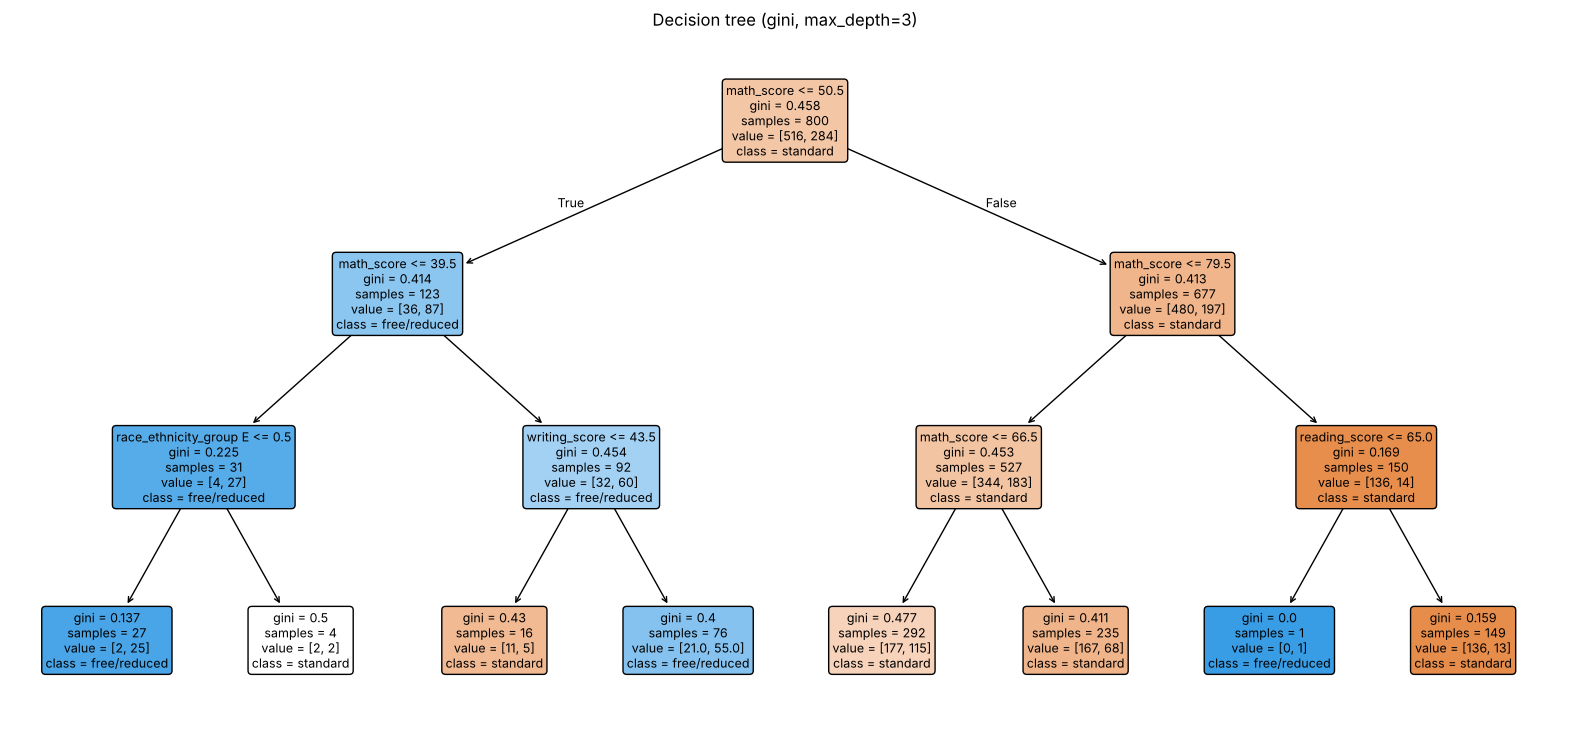

In [6]:
plt.figure(figsize=(20, 9))
plot_tree(model, feature_names=list(X.columns), class_names=["standard", "free/reduced"],
          filled=True, rounded=True, fontsize=9)
plt.title(f"Decision tree ({best['criterion']}, max_depth={int(best['max_depth'])})")
plt.savefig(FIG / "decision_tree.png", dpi=110, bbox_inches="tight")
plt.show()
print(export_text(model, feature_names=list(X.columns)))

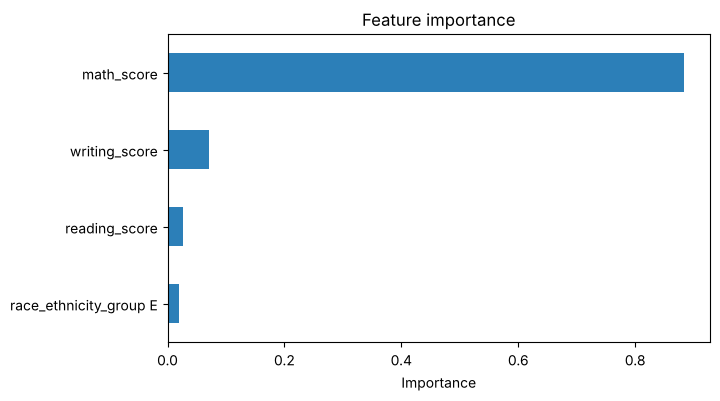

In [7]:
importance = pd.Series(model.feature_importances_, index=X.columns)
importance[importance > 0].sort_values().plot(kind="barh", figsize=(7, 4), color="#2c7fb8")
plt.title("Feature importance")
plt.xlabel("Importance")
plt.savefig(FIG / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Entropy, information gain and Gini calculated by hand

In [8]:
def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) + 0.0

def gini(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    return float(1 - (p ** 2).sum())

def best_threshold(values, labels):
    """Return (information gain, threshold) of the best binary split on one feature."""
    order = np.argsort(values)
    v, l = values[order], labels[order]
    base, top = entropy(l), (0.0, None)
    for i in range(1, len(v)):
        if v[i] == v[i - 1]:
            continue
        w = i / len(v)
        gain = base - (w * entropy(l[:i]) + (1 - w) * entropy(l[i:]))
        if gain > top[0]:
            top = (gain, (v[i] + v[i - 1]) / 2)
    return top

labels = y_tr.to_numpy()
print(f"Entropy of the training labels: {entropy(labels):.4f}")
print(f"Gini of the training labels   : {gini(labels):.4f}\n")

scan = pd.DataFrame(
    [(col, *best_threshold(X_tr[col].to_numpy(dtype=float), labels)) for col in X.columns],
    columns=["feature", "info_gain", "threshold"]).sort_values("info_gain", ascending=False)
print(scan.round(4).head(6).to_string(index=False))

Entropy of the training labels: 0.9385
Gini of the training labels   : 0.4579

               feature  info_gain  threshold
            math_score     0.0681       50.5
         writing_score     0.0475       66.5
         reading_score     0.0398       68.5
race_ethnicity_group E     0.0017        0.5
           gender_male     0.0011        0.5
race_ethnicity_group B     0.0007        0.5


In [9]:
stump = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_tr, y_tr)
root_feature = X.columns[stump.tree_.feature[0]]
root_threshold = stump.tree_.threshold[0]
print(f"scikit-learn root split : {root_feature} <= {root_threshold:.2f}")
print(f"My calculation          : {scan.iloc[0]['feature']} <= {scan.iloc[0]['threshold']:.2f}")

mask = X_tr[root_feature].to_numpy() <= root_threshold
left, right = labels[mask], labels[~mask]
w = len(left) / len(labels)
child_entropy = w * entropy(left) + (1 - w) * entropy(right)
child_gini = w * gini(left) + (1 - w) * gini(right)
print(f"\nLeft child : n={len(left)}  (free/reduced={int(left.sum())}), entropy={entropy(left):.4f}, gini={gini(left):.4f}")
print(f"Right child: n={len(right)}  (free/reduced={int(right.sum())}), entropy={entropy(right):.4f}, gini={gini(right):.4f}")
print(f"Information gain = {entropy(labels):.4f} - {child_entropy:.4f} = {entropy(labels) - child_entropy:.4f}")
print(f"Gini reduction   = {gini(labels):.4f} - {child_gini:.4f} = {gini(labels) - child_gini:.4f}")

scikit-learn root split : math_score <= 50.50
My calculation          : math_score <= 50.50

Left child : n=123  (free/reduced=87), entropy=0.8722, gini=0.4140
Right child: n=677  (free/reduced=197), entropy=0.8700, gini=0.4126
Information gain = 0.9385 - 0.8703 = 0.0681
Gini reduction   = 0.4579 - 0.4128 = 0.0451
